# PyTorch CNN - EuroSAT 이미지 분류
Keras CNN과 동일하게 Conv-BatchNorm-ReLU-MaxPool 블록을 3단 쌓은 구조입니다. 6개 모델 중 마지막입니다.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil

SPLIT_DIR = '/content/eurosat_split'
DRIVE_ZIP = '/content/drive/MyDrive/eurosat_split.zip'

if not os.path.exists(SPLIT_DIR) and os.path.exists(DRIVE_ZIP):
    shutil.unpack_archive(DRIVE_ZIP, SPLIT_DIR)
    print('Drive에서 압축 해제 완료')
else:
    print('SPLIT_DIR:', SPLIT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SPLIT_DIR: /content/eurosat_split


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('사용 device:', device)

IMG_SIZE = (64, 64)
BATCH_SIZE = 32

transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
])

train_dataset = datasets.ImageFolder(os.path.join(SPLIT_DIR, 'train'), transform=transform)
val_dataset = datasets.ImageFolder(os.path.join(SPLIT_DIR, 'val'), transform=transform)
test_dataset = datasets.ImageFolder(os.path.join(SPLIT_DIR, 'test'), transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

num_classes = len(train_dataset.classes)
print('클래스 수:', num_classes)

사용 device: cuda
클래스 수: 10


## CNN 모델 정의

In [ ]:
class CNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

def _init_weights(m):
    if isinstance(m, (nn.Linear, nn.Conv2d)):
        nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
        if m.bias is not None:
            nn.init.zeros_(m.bias)

model = CNN(num_classes).to(device)
model.apply(_init_weights)

num_params = sum(p.numel() for p in model.parameters())
print(model)
print(f'파라미터 수: {num_params:,}')

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)

def run_epoch(model, loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if train:
                optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)
    return total_loss / total, correct / total

In [ ]:
import time
import copy

MAX_EPOCHS = 50
PATIENCE = 5

history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}
best_val_loss = float('inf')
best_state = None
epochs_no_improve = 0

start_time = time.time()

for epoch in range(MAX_EPOCHS):
    train_loss, train_acc = run_epoch(model, train_loader, train=True)
    val_loss, val_acc = run_epoch(model, val_loader, train=False)
    scheduler.step(val_loss)

    history['loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['accuracy'].append(train_acc)
    history['val_accuracy'].append(val_acc)

    print(f'Epoch {epoch+1}: loss={train_loss:.4f} acc={train_acc:.4f} val_loss={val_loss:.4f} val_acc={val_acc:.4f}')

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print('EarlyStopping 발동')
            break

model.load_state_dict(best_state)
training_time = time.time() - start_time
print(f'학습 시간: {training_time:.1f}초')

Epoch 1: loss=1.5100 acc=0.4762 val_loss=0.7861 val_acc=0.7188
Epoch 2: loss=1.1231 acc=0.5908 val_loss=1.6915 val_acc=0.4677
Epoch 3: loss=1.0163 acc=0.6281 val_loss=1.2213 val_acc=0.5768
Epoch 4: loss=0.9472 acc=0.6568 val_loss=1.8636 val_acc=0.4674
Epoch 5: loss=0.8586 acc=0.6916 val_loss=0.9640 val_acc=0.6867
Epoch 6: loss=0.7479 acc=0.7260 val_loss=0.4673 val_acc=0.8402
Epoch 7: loss=0.6904 acc=0.7493 val_loss=0.5317 val_acc=0.8133
Epoch 8: loss=0.6709 acc=0.7597 val_loss=0.4002 val_acc=0.8731
Epoch 9: loss=0.6448 acc=0.7672 val_loss=0.3739 val_acc=0.8726
Epoch 10: loss=0.6140 acc=0.7769 val_loss=0.4726 val_acc=0.8393
Epoch 11: loss=0.5936 acc=0.7827 val_loss=0.3650 val_acc=0.8810
Epoch 12: loss=0.5605 acc=0.7965 val_loss=0.3785 val_acc=0.8686
Epoch 13: loss=0.5444 acc=0.7977 val_loss=0.7697 val_acc=0.7573
Epoch 14: loss=0.5367 acc=0.8077 val_loss=0.3112 val_acc=0.9030
Epoch 15: loss=0.5207 acc=0.8114 val_loss=0.4071 val_acc=0.8627
Epoch 16: loss=0.4900 acc=0.8192 val_loss=0.3330 

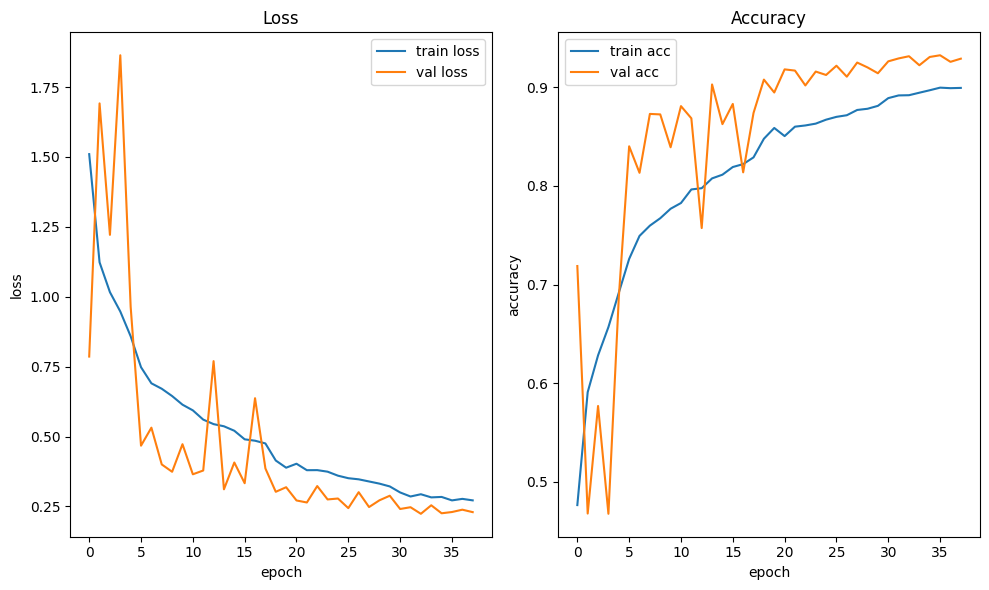

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].plot(history['loss'], label='train loss')
axes[0].plot(history['val_loss'], label='val loss')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('loss'); axes[0].legend(); axes[0].set_title('Loss')
axes[1].plot(history['accuracy'], label='train acc')
axes[1].plot(history['val_accuracy'], label='val acc')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('accuracy'); axes[1].legend(); axes[1].set_title('Accuracy')
plt.tight_layout();
plt.savefig('/content/pytorch_cnn_curve.jpg', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
test_loss, test_acc = run_epoch(model, test_loader, train=False)
print(f'Test accuracy: {test_acc:.4f}')
print(f'Test loss: {test_loss:.4f}')
print(f'파라미터 수: {num_params:,}')

Test accuracy: 0.9370
Test loss: 0.2094
파라미터 수: 2,193,674


In [ ]:
import pandas as pd

RESULTS_PATH = '/content/drive/MyDrive/model_results.csv'
row = {
    'model': 'CNN', 'framework': 'PyTorch',
    'test_accuracy': test_acc, 'test_loss': test_loss,
    'num_params': num_params, 'training_time_sec': training_time,
    'epochs_ran': len(history['loss']),
}

if os.path.exists(RESULTS_PATH):
    results_df = pd.read_csv(RESULTS_PATH)
    results_df = results_df[~((results_df['model'] == row['model']) & (results_df['framework'] == row['framework']))]
    results_df = pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)
else:
    results_df = pd.DataFrame([row])

results_df.to_csv(RESULTS_PATH, index=False)
results_df

,model,framework,test_accuracy,test_loss,num_params,training_time_sec,epochs_ran
0,ANN,Keras,0.273827,1.791635,3148554,65.389723,28
1,DNN,Keras,0.390864,1.600345,6457482,71.961101,23
2,ANN,PyTorch,0.216296,1.917291,3148554,130.308418,11
3,DNN,PyTorch,0.290617,1.760557,6457482,144.349892,11
4,CNN,Keras,0.909383,0.311695,2194122,87.861347,15
5,CNN,PyTorch,0.937037,0.209416,2193674,582.438936,38


In [ ]:
PYTORCH_CNN_PATH = '/content/drive/MyDrive/pytorch_cnn_model.pt'
torch.save(model.state_dict(), PYTORCH_CNN_PATH)
print('저장 완료:', PYTORCH_CNN_PATH)

저장 완료: /content/drive/MyDrive/pytorch_cnn_model.pt
